In [ ]:
from google.colab import drive
drive.mount("/content/drive")

#Download new dataset from kaggle

In [ ]:
!pip install opendatasets --quiet

In [ ]:
import opendatasets as od
data_url_1 = "https://www.kaggle.com/datasets/imranlaskar123/binary-waste-classification-dataset"
data_url_2 = "https://www.kaggle.com/datasets/imranlaskar123/binary-waste-classification-dataset"
od.download(data_url_2)

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: suisd
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/imranlaskar123/binary-waste-classification-dataset


100%|██████████| 9.68G/9.68G [01:38<00:00, 106MB/s] 


In [ ]:
from PIL import Image
import os


def resize_imgs(src_dir, dest_dir):
  skip_count = 0
  print("Start resizing")

  for class_name in os.listdir(src_dir):
    os.makedirs(os.path.join(dest_dir , class_name) , exist_ok=True)
    class_path = os.path.join(src_dir , class_name)

    for img_name in os.listdir(class_path):
      img_path =os.path.join(class_path , img_name)

      try:
        img = Image.open(img_path).convert("RGB")
        img =img.resize((256 ,256))
        img.save(os.path.join(dest_dir,class_name,img_name))

      except Exception as e:
        print(f"Skipped {img_name}: {e}")
        skip_count=skip_count+1


  print(f"total skipp:{skip_count}")
print("Done!")

Done!


In [ ]:
import os
os.makedirs("copy_data",exist_ok =True)
os.makedirs("/content/copy_data/dataset",exist_ok=True)
os.makedirs("/content/copy_data/dataset/train",exist_ok = True)
os.makedirs("/content/copy_data/dataset/test" , exist_ok = True)

In [ ]:
test_path ="/content/binary-waste-classification-dataset/home/imran/Downloads/Copy of dataset/dataset/test"
test_dest_path ="/content/copy_data/dataset/test"
resize_imgs(test_path ,test_dest_path )

Start resizing
total skipp:0


In [ ]:
train_path = "/content/binary-waste-classification-dataset/home/imran/Downloads/Copy of dataset/dataset/train"
train_dest_path ="/content/copy_data/dataset/train"
resize_imgs(train_path , train_dest_path)

Start resizing
total skipp:0


In [ ]:
import os
import torch

In [ ]:
from pathlib import Path
folder_name = 'dataset'
data_path = Path("copy_data")
img_path = data_path/folder_name
img_path

PosixPath('copy_data/dataset')

In [ ]:
def walk_through_data(dir_path):
  for dirpath ,dirnames ,filenames in os.walk(dir_path):
    print(f"There are {len(dirnames)} directories and {len(filenames)} images in {dirpath} ")

In [ ]:
walk_through_data(img_path)

There are 2 directories and 0 images in copy_data/dataset 
There are 2 directories and 0 images in copy_data/dataset/train 
There are 0 directories and 9571 images in copy_data/dataset/train/Not_Waste 
There are 0 directories and 10824 images in copy_data/dataset/train/Waste 
There are 2 directories and 0 images in copy_data/dataset/test 
There are 0 directories and 1543 images in copy_data/dataset/test/Not_Waste 
There are 0 directories and 2050 images in copy_data/dataset/test/Waste 


In [ ]:
train_dir = img_path/"train"
test_dir = img_path/"test"

In [ ]:
img_path

PosixPath('copy_data/dataset')

##Open a random image using file path


Image path copy_data/dataset/train/Waste/MFC_RGB_0108_bmp_jpg.rf.cxD5Vc7zx3e5h1UdZi1s.jpg
Image Class: Waste
Image Height: 256
Image width: 256


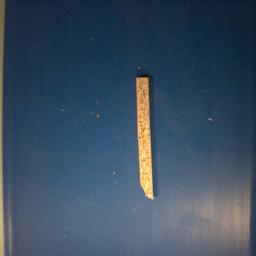

In [ ]:
import random
from  PIL import Image

img_path_list = list(img_path.glob("*/*/*.jpg"))
rand_img_path = random.choice(img_path_list)
class_name = rand_img_path.parent.stem
img = Image.open(rand_img_path)
print(f"Image path {rand_img_path}")
print(f"Image Class: {class_name}")
print(f"Image Height: {img.height}")
print(f"Image width: {img.width}")
img

(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

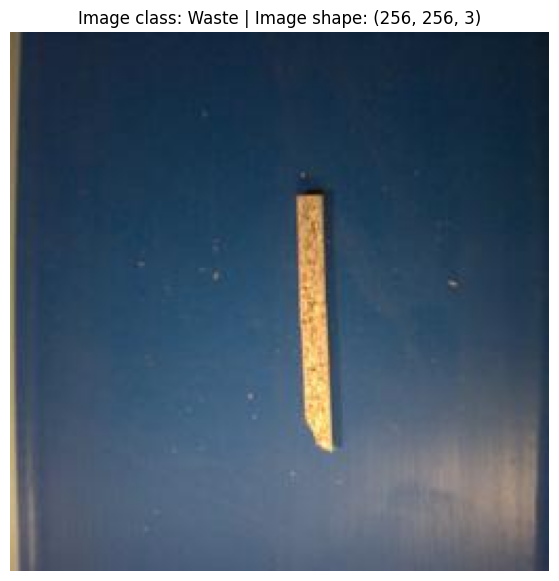

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


img_array = np.array(img)

plt.figure(figsize=(8,7))

plt.imshow(img_array)
plt.title(f"Image class: {class_name} | Image shape: {img_array.shape}")
plt.axis(False)


## Make the transform fucntion to tramsform the image

In [ ]:
from torchvision import datasets , transforms

train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.RandomHorizontalFlip( p=0.5)

])
test_transform = transforms.Compose([
    transforms.ToTensor()
])
train_transform , test_transform

(Compose(
     ToTensor()
     RandomHorizontalFlip(p=0.5)
 ),
 Compose(
     ToTensor()
 ))

In [ ]:
trans_img = train_transform(img)
trans_img

tensor([[[0.0471, 0.0471, 0.0392,  ..., 0.4235, 0.4235, 0.4431],
         [0.0510, 0.0510, 0.0471,  ..., 0.4235, 0.4235, 0.4431],
         [0.0549, 0.0549, 0.0510,  ..., 0.4235, 0.4275, 0.4471],
         ...,
         [0.1608, 0.1569, 0.1647,  ..., 0.7176, 0.7176, 0.7373],
         [0.1647, 0.1608, 0.1686,  ..., 0.7137, 0.7176, 0.7333],
         [0.1686, 0.1647, 0.1686,  ..., 0.7137, 0.7176, 0.7333]],

        [[0.0941, 0.0941, 0.0941,  ..., 0.3765, 0.3647, 0.3804],
         [0.0980, 0.0980, 0.1020,  ..., 0.3765, 0.3647, 0.3804],
         [0.1020, 0.1020, 0.1059,  ..., 0.3765, 0.3686, 0.3843],
         ...,
         [0.2078, 0.1961, 0.2078,  ..., 0.6392, 0.6275, 0.6353],
         [0.2118, 0.2000, 0.2118,  ..., 0.6353, 0.6275, 0.6314],
         [0.2157, 0.2039, 0.2118,  ..., 0.6353, 0.6275, 0.6314]],

        [[0.1490, 0.1490, 0.1451,  ..., 0.2824, 0.2510, 0.2510],
         [0.1529, 0.1529, 0.1529,  ..., 0.2824, 0.2510, 0.2510],
         [0.1569, 0.1569, 0.1569,  ..., 0.2824, 0.2549, 0.

(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

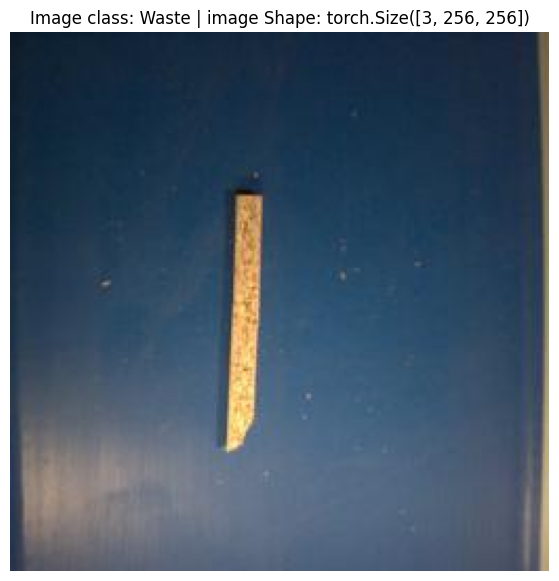

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,7))
plt.imshow(trans_img.permute(1,2,0).numpy())
plt.title(f"Image class: {class_name} | image Shape: {trans_img.shape}")
plt.axis(False)

##Loading the image Data using ImageFolder Madule

In [ ]:
train_dir , test_dir

(PosixPath('copy_data/dataset/train'), PosixPath('copy_data/dataset/test'))

In [ ]:
from torchvision.datasets import ImageFolder
train_data = ImageFolder(root = train_dir , transform = train_transform ,target_transform = None)
test_data = ImageFolder(root = test_dir , transform = test_transform , target_transform = None)



In [ ]:
train_data , test_data

(Dataset ImageFolder
     Number of datapoints: 20395
     Root location: copy_data/dataset/train
     StandardTransform
 Transform: Compose(
                ToTensor()
                RandomHorizontalFlip(p=0.5)
            ),
 Dataset ImageFolder
     Number of datapoints: 3593
     Root location: copy_data/dataset/test
     StandardTransform
 Transform: Compose(
                ToTensor()
            ))

In [ ]:
class_names = train_data.classes
class_names

['Not_Waste', 'Waste']

In [ ]:
class_name_idx = train_data.class_to_idx
class_name_idx

{'Not_Waste': 0, 'Waste': 1}

In [ ]:
len(train_data) ,len(test_data)

(20395, 3593)

(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

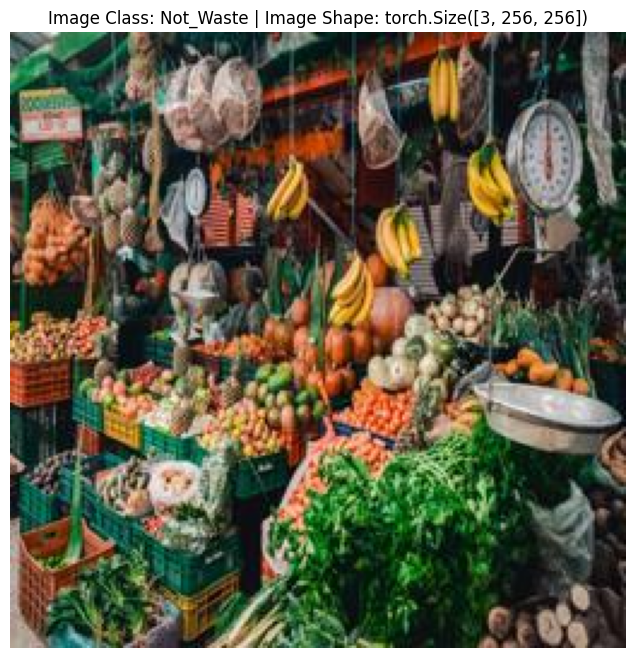

In [ ]:
import random
rand_sample = random.choice(train_data)
load_img , load_class_name = rand_sample[0],rand_sample[1]
plt.figure(figsize=(10,8))
plt.imshow(load_img.permute(1,2,0).numpy())
plt.title(f"Image Class: {class_names[load_class_name]} | Image Shape: {load_img.shape}")
plt.axis(False)

## Load and Batch the data using DataLoader Madule

In [ ]:
from torch.utils.data import DataLoader
import os
BATCH_SIZE =64
NUM_WORKERS =os.cpu_count()

train_dataloader = DataLoader(dataset = train_data , batch_size = BATCH_SIZE , shuffle = True , num_workers= NUM_WORKERS)
test_dataloader = DataLoader(dataset = test_data , batch_size = BATCH_SIZE , shuffle = True , num_workers = NUM_WORKERS)

train_dataloader , test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7b0fba9e5130>,
 <torch.utils.data.dataloader.DataLoader at 0x7b0fcfb489b0>)

In [ ]:
len(train_dataloader) ,len(test_dataloader)

(319, 57)

In [ ]:
len(train_data)/64 , len(test_data)/64

(318.671875, 56.140625)

In [ ]:
train_feature_batch , train_label_batch = next(iter(train_dataloader))
train_feature_batch.shape , train_label_batch.shape

(torch.Size([64, 3, 256, 256]), torch.Size([64]))

In [ ]:
train_feature_batch[2] , train_label_batch[2]

(tensor([[[0.2118, 0.1961, 0.2039,  ..., 0.9608, 0.9490, 0.8196],
          [0.1765, 0.1843, 0.1882,  ..., 0.8824, 0.8510, 0.8000],
          [0.1451, 0.1686, 0.1765,  ..., 0.8235, 0.7098, 0.6275],
          ...,
          [0.6745, 0.8039, 0.9216,  ..., 0.0510, 0.0627, 0.0745],
          [0.2980, 0.3333, 0.4235,  ..., 0.1098, 0.1059, 0.1059],
          [0.1490, 0.0784, 0.0824,  ..., 0.1725, 0.1333, 0.0510]],
 
         [[0.2118, 0.2078, 0.2196,  ..., 0.9843, 0.9725, 0.8431],
          [0.1765, 0.1961, 0.2039,  ..., 0.9059, 0.8745, 0.8235],
          [0.1569, 0.1882, 0.2000,  ..., 0.8471, 0.7333, 0.6510],
          ...,
          [0.5569, 0.6863, 0.7922,  ..., 0.0000, 0.0000, 0.0000],
          [0.1843, 0.2196, 0.3098,  ..., 0.0510, 0.0353, 0.0314],
          [0.0431, 0.0000, 0.0000,  ..., 0.1176, 0.0627, 0.0000]],
 
         [[0.1020, 0.1020, 0.1294,  ..., 0.9686, 0.9569, 0.8275],
          [0.0667, 0.0902, 0.1137,  ..., 0.8902, 0.8588, 0.8078],
          [0.0353, 0.0706, 0.0980,  ...,

##Plot random imgage

In [ ]:
import torch
def plot_rand_img(data:torch.utils.data.Dataset , n:int,
                  classes:list , seed:int = None ):


  if (n >6):
    n = 6
    print("For display perpass we are making the n = 6")
  if seed:
    random.seed(seed)



  rand_idx = random.sample(range(len(data)), k =n)

  plt.figure(figsize=(16,7))

  for i , targ_idx , in enumerate(rand_idx):
    targ_img , targ_label = data[targ_idx][0],data[targ_idx][1]

    img_premute = targ_img.permute(1,2,0).numpy()

    plt.subplot(1, n ,i+1)

    plt.imshow(img_premute)

    plt.title(f"image class: {classes[targ_label]}")
    plt.axis(False)


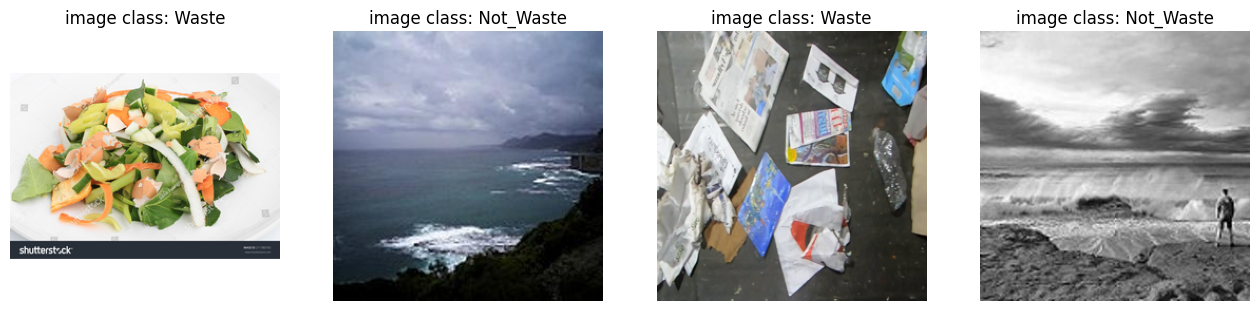

In [ ]:
plot_rand_img(data=train_data , n = 4 , classes = class_names)

In [ ]:
device = ''
if torch.cuda.is_available():
  device = 'cuda'
else:
  device = 'cpu'

In [ ]:
device

'cuda'

In [ ]:
torch.cuda.is_available()

True

## Train set and test set

In [ ]:
def train_step(model:torch.nn.Module , dataloader:torch.utils.data.Dataset ,
               loss_fn: torch.nn.Module  , optimizer: torch.optim.Optimizer,
               device: torch.device =device):
  model.train()
  train_loss , train_acc , = 0, 0

  for batch ,(X,y) in enumerate(dataloader):
    X ,y = X.to(device),y.to(device)
    y_preds = model(X)
    loss = loss_fn(y_preds  , y)
    train_loss += loss.item()

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    y_pred_class = torch.argmax(torch.softmax(y_preds, dim=1), dim=1)
    train_acc += (y_pred_class == y).sum().item()/len(y_preds)

  train_loss/=len(dataloader)
  train_acc/=len(dataloader)


  return train_loss , train_acc


In [ ]:
def test_step(model:torch.nn.Module ,
              dataloader: torch.utils.data.DataLoader ,
              loss_fn: torch.nn.Module ,
              device: torch.device = device):
  test_loss , test_acc = 0,0
  model.eval()
  with torch.inference_mode():
    for X,y in dataloader:

      X , y = X.to(device),y.to(device)

      test_preds = model(X)
      loss = loss_fn(test_preds , y)
      test_loss +=loss

      y_pred_class = torch.argmax(torch.softmax(test_preds, dim=1), dim=1)

      test_acc += (y_pred_class == y).sum().item()/len(test_preds)

    test_loss /=len(dataloader)
    test_acc /=len(dataloader)

  return test_loss , test_acc




In [ ]:
def train_loop(model:torch.nn.Module ,
               train_dataloader:torch.utils.data.DataLoader ,
               test_dataloader:torch.utils.data.DataLoader ,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device:torch.device = device,
               epochs:int = 5
               ):
  result ={
      'Train Loss':[],
      'Train Acc':[],
      'Test Loss':[],
      'Test Acc':[]
  }

  for epoch in range(epochs):
    print(f"Epoch: {epoch}\n..............")


    train_loss , train_acc = train_step(model= model ,
               dataloader =train_dataloader ,
               loss_fn = loss_fn , optimizer = optimizer)

    test_loss , test_acc = test_step(model = model ,
              dataloader =test_dataloader ,
              loss_fn = loss_fn)
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f} | Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}")

    result["Train Loss"].append(train_loss)
    result["Train Acc"].append(train_acc)
    result["Test Loss"].append(test_loss)
    result["Test Acc"].append(test_acc)

  return result



In [ ]:
import torch
from pathlib import Path

def save_model(name , model):
  MODEL_PATH = Path("/content/drive/MyDrive/waste_classification_models")
  MODEL_PATH.mkdir(parents=True, exist_ok=True)


  MODEL_NAME = name + ".pt"
  MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME


  print(f"Saving model to: {MODEL_SAVE_PATH}")
  torch.save(obj=model.state_dict(), f=MODEL_SAVE_PATH)
  print("Model saved successfully in .pt format!")

In [ ]:
!pip install scikit-learn --quiet

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

#Test the model with Real world images without labels and filter

In [ ]:
import os
from PIL import  Image
import torch

In [ ]:
test_image_path ="/content/drive/MyDrive/Classification_data_set"

In [ ]:
from torchvision import transforms
test_image_transform =  transforms.Compose([
    transforms.ToTensor()

])

In [ ]:
from torchvision.datasets import ImageFolder
test_images_data = ImageFolder(root=test_image_path , transform=test_image_transform , target_transform =None)

In [ ]:
test_images_data

Dataset ImageFolder
    Number of datapoints: 207
    Root location: /content/drive/MyDrive/Classification_data_set
    StandardTransform
Transform: Compose(
               ToTensor()
           )

In [ ]:
class_names=["not_waste" , "waste" ]

In [ ]:
model_1_loaded= model_1_loaded.to(device)

In [ ]:
import random
import matplotlib.pyplot as plt
import torch

def visualize_predictions(model, dataset,class_names,device,num_images=20,rows=4,cols=5):
    model.eval()
    random_indices = random.sample(range(len(dataset)), num_images)
    plt.figure(figsize=(20, 15))

    for i, idx in enumerate(random_indices):
        image, label = dataset[idx]
        img_tensor = image.unsqueeze(0).to(device)

        with torch.inference_mode():
            output = model(img_tensor)
            probs = torch.softmax(output, dim=1)
            confidence, pred = torch.max(probs, dim=1)
        plt.subplot(rows, cols, i + 1)
        plt.imshow(image.permute(1, 2, 0))
        plt.axis("off")

        plt.title(
            f"Pred: {class_names[pred.item()]}\n"
            f"Conf: {confidence.item()*100:.2f}%"
        )
    plt.tight_layout()
    plt.show()

# Model_4 is train on 25k images and 5 epoch to reduce overfitting lr=0.0001 and Optimizer use is Adam optimizer loss function is CrossEntropyLoss

In [ ]:
from torchvision.models import mobilenet_v3_small
model_4 = mobilenet_v3_small(weights= "DEFAULT")
model_4.classifier[3]=torch.nn.Linear(1024 ,2)
model_4 = model_4.to(device)

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer =torch.optim.Adam(params=model_4.parameters(),lr =0.0001)

In [ ]:
train_loop(
    model=model_4,
    train_dataloader = train_dataloader,
    test_dataloader = test_dataloader ,
    loss_fn = loss_fn ,
    optimizer = optimizer,
    epochs = 5
)

Epoch: 0
..............
Train Loss: 0.0922 | Train Acc: 0.97 | Test Loss: 0.1992 | Test Acc: 0.94
Epoch: 1
..............
Train Loss: 0.0187 | Train Acc: 0.99 | Test Loss: 0.1899 | Test Acc: 0.95
Epoch: 2
..............
Train Loss: 0.0099 | Train Acc: 1.00 | Test Loss: 0.2954 | Test Acc: 0.94
Epoch: 3
..............
Train Loss: 0.0062 | Train Acc: 1.00 | Test Loss: 0.2912 | Test Acc: 0.95
Epoch: 4
..............
Train Loss: 0.0051 | Train Acc: 1.00 | Test Loss: 0.2871 | Test Acc: 0.95


{'Train Loss': [0.09224880699850736,
  0.01872383106087895,
  0.009871979678215913,
  0.0062003153529486925,
  0.005123388553528853],
 'Train Acc': [0.9672566432164468,
  0.9943181818181818,
  0.9971590909090909,
  0.9981387147335423,
  0.9985317033607932],
 'Test Loss': [tensor(0.1992, device='cuda:0'),
  tensor(0.1899, device='cuda:0'),
  tensor(0.2954, device='cuda:0'),
  tensor(0.2912, device='cuda:0'),
  tensor(0.2871, device='cuda:0')],
 'Test Acc': [0.9350024366471734,
  0.9484649122807017,
  0.9415813840155944,
  0.9470638401559454,
  0.9470942982456141]}

In [ ]:
save_model(name="model_4",model=model_4)

Saving model to: /content/drive/MyDrive/waste_classification_models/model_4.pt
Model saved successfully in .pt format!


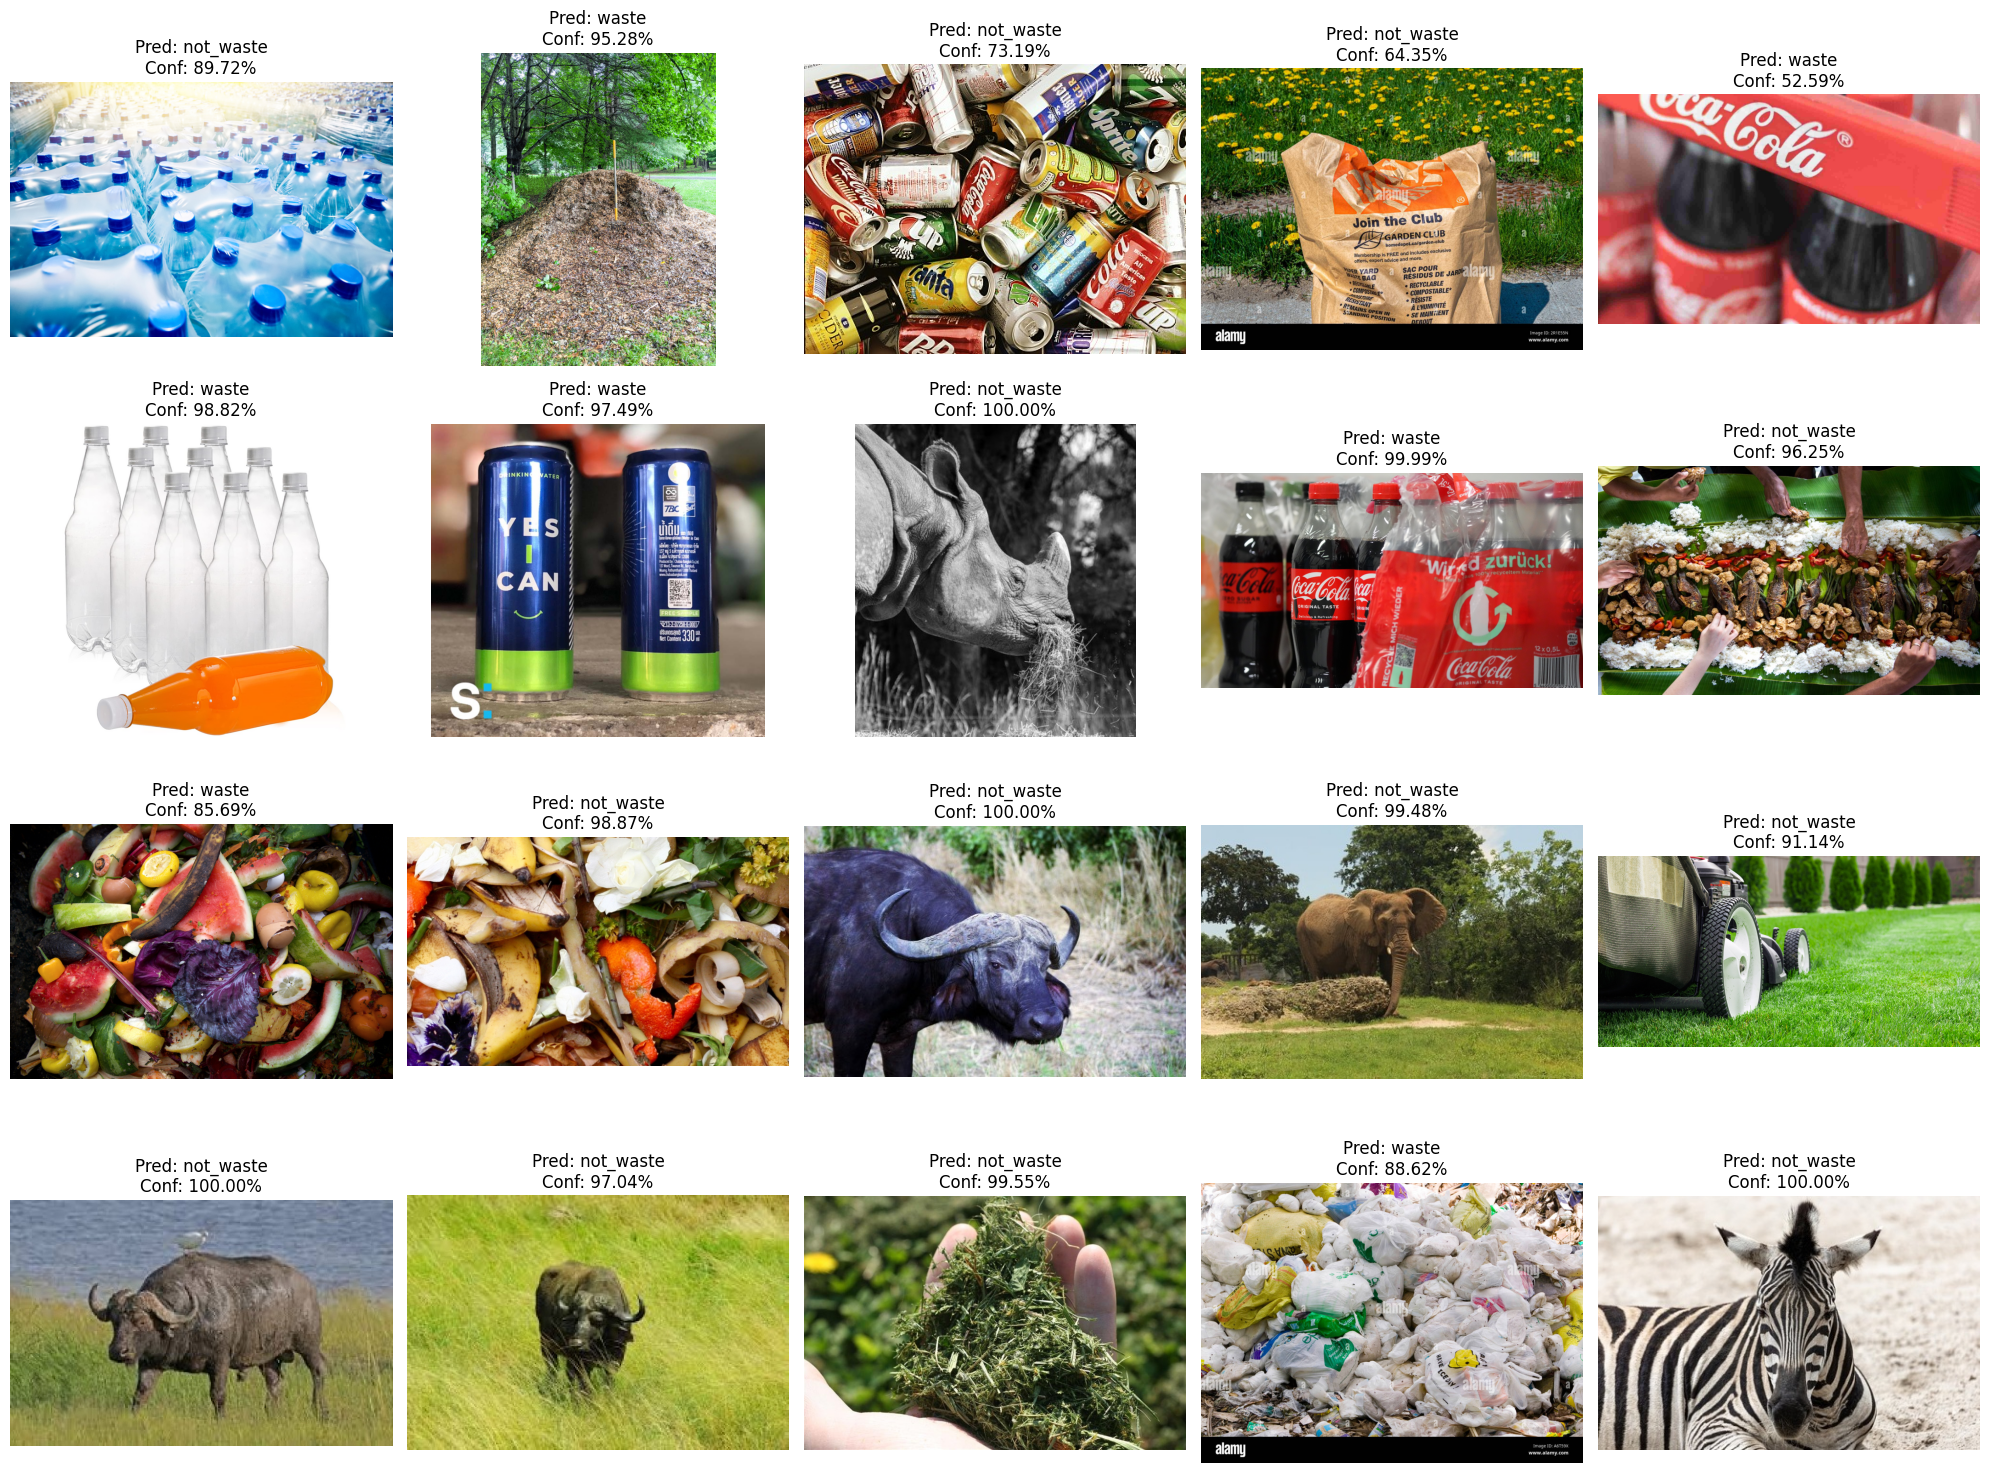

In [ ]:
visualize_predictions(model=model_4 , dataset=test_images_data , class_names = class_names , device= device)

In [ ]:
import torch
from torchvision.models import mobilenet_v3_small
from pathlib import Path
model_4_loaded = mobilenet_v3_small(weights=None)
model_4_loaded.classifier[3] = torch.nn.Linear(1024, 2)

MODEL_PATH = Path("/content/drive/MyDrive/waste_classification_models")
MODEL_NAME = "model_4.pt"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME


print(f"Loading model from: {MODEL_SAVE_PATH}")
model_4_loaded.load_state_dict(torch.load(MODEL_SAVE_PATH))
model_4_loaded = model_4_loaded.to(device)

print("Model loaded successfully!")

In [ ]:
import torch
model_4_loaded.eval()
y_true =[]
y_pred =[]

with torch.no_grad():
  for X,y in test_dataloader:
    X= X.to(device)
    y=y.to(device)
    outputs = model_4_loaded(X)
    preds = torch.argmax(outputs ,dim=1)
    y_true.extend(y.cpu().numpy())
    y_pred.extend(preds.cpu().numpy())

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def Eval_matrix(y_true ,y_pred):

  accuracy = accuracy_score(y_true,y_pred)
  precision = precision_score(y_true ,y_pred)
  recall = recall_score(y_true , y_pred)
  f1 = f1_score(y_true , y_pred)
  cm = confusion_matrix(y_true , y_pred)

  print("Accuracy: ",accuracy)
  print("Precision: ",precision )
  print("Recall: ",recall)
  print("F1: ",f1)
  print("Confusion matrix: \n \n",cm)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
cm = confusion_matrix(y_true , y_pred)

In [ ]:
plt.figure(figsize=(6,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Waste","Waste"],
    yticklabels=["Not Waste","Waste"]

)
plt.xlabel("Predicted")
plt.ylabel("ACtuals")
plt.title("Confusion Matrix")
plt.show()